# Acceso al hospital, transporte público y marginación en Sonora

¿Cuántas personas viven en localidades con traslados hospitalarios largos y sin transporte público foráneo? ¿Cómo se distribuye esta barrera según el grado de marginación?

La población proviene de ITER 2020. INEGI RESLOC 2020 describe la movilidad a escala de localidad. CONAPO aporta el índice de marginación 2020. La tabla de accesibilidad del proyecto identifica la unidad hospitalaria y registra el método de cálculo de los traslados. El tiempo de RESLOC corresponde al viaje a la cabecera municipal. Los tiempos hospitalarios corresponden al traslado en automóvil.

[Fuentes y preparación de los datos](../docs/workflow.md) · [Diccionario de accesibilidad](../references/diccionario_accesibilidad_localidades.md)

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")

inicio = Path.cwd().resolve()
raiz = next(ruta for ruta in (inicio, *inicio.parents) if (ruta / "config/fuentes_health.yaml").is_file())
sys.path.insert(0, str(raiz / "src"))
from health_data.config import cargar_configuracion

procesados = raiz / "data/processed"
umbral = cargar_configuracion().umbrales.tiempo_critico_segundo_nivel_min
archivos = {
    "accesibilidad": "accesibilidad_localidades.parquet",
    "transporte": "inegi-resloc-001_localidades.parquet",
    "marginación": "conapo-marg-001_localidades.parquet",
}
faltantes = [nombre for nombre in archivos.values() if not (procesados / nombre).is_file()]
if faltantes:
    raise FileNotFoundError(f"Genere primero los Parquet del proyecto. Faltan {', '.join(faltantes)}.")

acceso = pd.read_parquet(procesados / archivos["accesibilidad"])
transporte = pd.read_parquet(procesados / archivos["transporte"])
margen = pd.read_parquet(procesados / archivos["marginación"])

for tabla, clave in ((acceso, "locality_id"), (transporte, "cvegeo"), (margen, "cvegeo")):
    tabla[clave] = tabla[clave].astype("string")
    if not tabla[clave].str.fullmatch(r"26[0-9]{7}").fillna(False).all() or not tabla[clave].is_unique:
        raise ValueError(f"Se esperaba una fila por clave válida de localidad de Sonora en {clave}.")

localidades = (
    acceso.merge(transporte.rename(columns={"cvegeo": "locality_id"}), on="locality_id",
                 how="left", validate="one_to_one", indicator="cruce_transporte")
    .merge(margen.rename(columns={"cvegeo": "locality_id"}), on="locality_id",
           how="left", validate="one_to_one", indicator="cruce_marginacion")
)
assert len(localidades) == len(acceso)
assert localidades["population"].sum() == acceso["population"].sum()
localidades["secondary_time_min"] = pd.to_numeric(localidades["secondary_time_min"], errors="coerce")
localidades["demora"] = localidades["secondary_time_min"].astype("Float64").gt(umbral)
localidades["estado_transporte"] = localidades["transporte_foraneo"].fillna("SIN RESPUESTA")
localidades.loc[localidades["cruce_transporte"].eq("left_only"), "estado_transporte"] = "SIN CRUCE"
localidades["grado"] = localidades["grado_marginacion"].astype("string").str.strip().str.upper()

medios_cabecera = localidades[[columna for columna in transporte if columna.endswith("_a_cabecera")]]
sin_servicio = medios_cabecera.eq("NO").any(axis=1) & ~medios_cabecera.eq("NO ESPECIFICADO").any(axis=1)
localidades["servicio_cabecera"] = "SIN DATO"
localidades.loc[sin_servicio | localidades["estado_transporte"].eq("NO"), "servicio_cabecera"] = "NO"
localidades.loc[medios_cabecera.eq("SI").any(axis=1), "servicio_cabecera"] = "SI"

## Cobertura y método de traslado

Los cruces conservan el universo y la población de la tabla de accesibilidad. Una localidad puede coincidir con la fuente y tener una respuesta sin especificar. La cobertura se mide tanto sobre localidades como sobre personas, ya que el tamaño de las localidades varía.

In [2]:
def resumen(filas):
    return {"localidades": len(filas), "personas": int(filas["population"].sum())}

cobertura = pd.DataFrame({
    "Universo de accesibilidad": resumen(localidades),
    "Coinciden con RESLOC": resumen(localidades[localidades["cruce_transporte"].eq("both")]),
    "Transporte con respuesta sí o no": resumen(localidades[localidades["estado_transporte"].isin(["SI", "NO"])]),
    "Coinciden con CONAPO": resumen(localidades[localidades["cruce_marginacion"].eq("both")]),
    "Con grado de marginación": resumen(localidades[localidades["grado"].notna()]),
    "Con tiempo hospitalario": resumen(localidades[localidades["demora"].notna()]),
}).T
cobertura["% de localidades"] = (100 * cobertura["localidades"] / len(localidades)).round(1)
cobertura["% de personas"] = (100 * cobertura["personas"] / localidades["population"].sum()).round(1)
display(cobertura)

metodos = (
    localidades.groupby(localidades["secondary_method"].fillna("Sin método"), observed=True)
    .agg(localidades=("locality_id", "size"), personas=("population", "sum"))
)
display(metodos)
cuota_sakbe = 100 * localidades["secondary_method"].eq("sakbe").fillna(False).mean()
display(Markdown(
    f"**Cobertura SAKBÉ para hospital: {cuota_sakbe:.1f} % de las localidades.** "
    "Los resultados dependen de los métodos que aparecen en la tabla. "
    "Cuando la cobertura SAKBÉ es cero, son resultados exploratorios del modelo de estimación del proyecto."
))

,localidades,personas,% de localidades,% de personas
Universo de accesibilidad,7297,2944824,100.0,100.0
Coinciden con RESLOC,7167,315223,98.2,10.7
Transporte con respuesta sí o no,5401,297784,74.0,10.1
Coinciden con CONAPO,1850,2921049,25.4,99.2
Con grado de marginación,1850,2921049,25.4,99.2
Con tiempo hospitalario,7297,2944824,100.0,100.0


,localidades,personas
secondary_method,,
estimado,7297,2944824


**Cobertura SAKBÉ para hospital: 0.0 % de las localidades.** Los resultados dependen de los métodos que aparecen en la tabla. Cuando la cobertura SAKBÉ es cero, son resultados exploratorios del modelo de estimación del proyecto.

## Doble barrera de acceso

La doble barrera se define como un traslado hospitalario superior al umbral configurado y ausencia explícita de transporte foráneo en RESLOC. El ranking municipal cuenta a las personas que viven en esas localidades. El conteo de viviendas sin automóvil ni motocicleta usa los registros publicados de ITER.

Para el servicio directo a la cabecera, basta un medio con respuesta afirmativa para confirmar servicio. Se registra ausencia cuando la fuente reporta falta de transporte foráneo o cuando los medios informados tienen respuesta negativa y ninguno está sin especificar. Las demás localidades quedan sin dato.

In [3]:
lejos = localidades.loc[localidades["demora"].fillna(False)].copy()
cruce_transporte = lejos.groupby("estado_transporte", observed=True).agg(
    localidades=("locality_id", "size"), personas=("population", "sum")
).sort_values("personas", ascending=False)
display(cruce_transporte)

servicio = lejos.groupby("servicio_cabecera", observed=True).agg(
    localidades=("locality_id", "size"), personas=("population", "sum")
)
display(servicio)

doble = lejos.loc[lejos["estado_transporte"].eq("NO")]
viviendas_publicadas = doble["viviendas_sin_auto_ni_moto"].dropna()
if not viviendas_publicadas.empty:
    display(Markdown(
        f"ITER publica el conteo de viviendas sin automóvil ni motocicleta en "
        f"{len(viviendas_publicadas):,} de las {len(doble):,} localidades con doble barrera. "
        f"En esa parte de la cobertura se contabilizan **{viviendas_publicadas.sum():,.0f} viviendas**."
    ))
ranking = (
    doble.groupby("municipality_name", observed=True)
    .agg(localidades=("locality_id", "size"), personas=("population", "sum"),
         maximo_min=("secondary_time_min", "max"))
    .sort_values(["personas", "localidades"], ascending=False)
)
display(ranking.head(15).round(1))
display(doble.nlargest(15, "population")[
    ["locality_id", "locality_name", "municipality_name", "population", "secondary_time_min",
     "secondary_method", "grado", "viviendas_sin_auto_ni_moto"]
].round(1))
display(Markdown(
    f"Con el umbral de **más de {umbral:g} minutos**, la doble barrera reúne "
    f"**{doble['population'].sum():,} personas en {len(doble):,} localidades**. "
    f"La suma de personas incluye a quienes viven en esas localidades según ITER 2020."
))

,localidades,personas
estado_transporte,,
SIN CRUCE,10,12033
NO,195,5962
SI,26,3584
NO ESPECIFICADO,155,612


,localidades,personas
servicio_cabecera,,
NO,197,6321
SI,24,3225
SIN DATO,165,12645


ITER publica el conteo de viviendas sin automóvil ni motocicleta en 56 de las 195 localidades con doble barrera. En esa parte de la cobertura se contabilizan **690 viviendas**.

,localidades,personas,maximo_min
municipality_name,,,
General Plutarco Elías Calles,34,1318,155.9
Yécora,25,988,215.2
Sahuaripa,15,920,211.6
Soyopa,6,627,165.4
Nácori Chico,7,520,137.4
Pitiquito,50,487,165.0
Arivechi,2,410,178.8
Rosario,21,258,149.3
Bacanora,9,239,182.9


,locality_id,locality_name,municipality_name,population,secondary_time_min,secondary_method,grado,viviendas_sin_auto_ni_moto
7028,260700019,El Desierto de Sonora,General Plutarco Elías Calles,901,120.2,estimado,BAJO,72.0
4802,260400017,La Mesa Tres Ríos,Nácori Chico,463,126.7,estimado,MEDIO,36.0
482,260050006,Tarachi,Arivechi,374,178.8,estimado,BAJO,36.0
5906,260520044,Matarachi,Sahuaripa,334,202.5,estimado,MEDIO,24.0
5468,260470027,Desemboque de los Seris (El Desemboque),Pitiquito,329,157.0,estimado,BAJO,55.0
6629,260610009,San Antonio de la Huerta,Soyopa,297,157.8,estimado,MUY BAJO,25.0
6630,260610011,Tónichi,Soyopa,280,165.4,estimado,MUY BAJO,30.0
6970,260690042,Santa Rosa (Santa Rosa de Lima),Yécora,208,181.8,estimado,MUY BAJO,37.0
5908,260520054,Seguadehuachi,Sahuaripa,195,135.4,estimado,MUY BAJO,12.0
6957,260690017,Guadalupe de Tayopa,Yécora,161,161.1,estimado,BAJO,30.0


Con el umbral de **más de 120 minutos**, la doble barrera reúne **5,962 personas en 195 localidades**. La suma de personas incluye a quienes viven en esas localidades según ITER 2020.

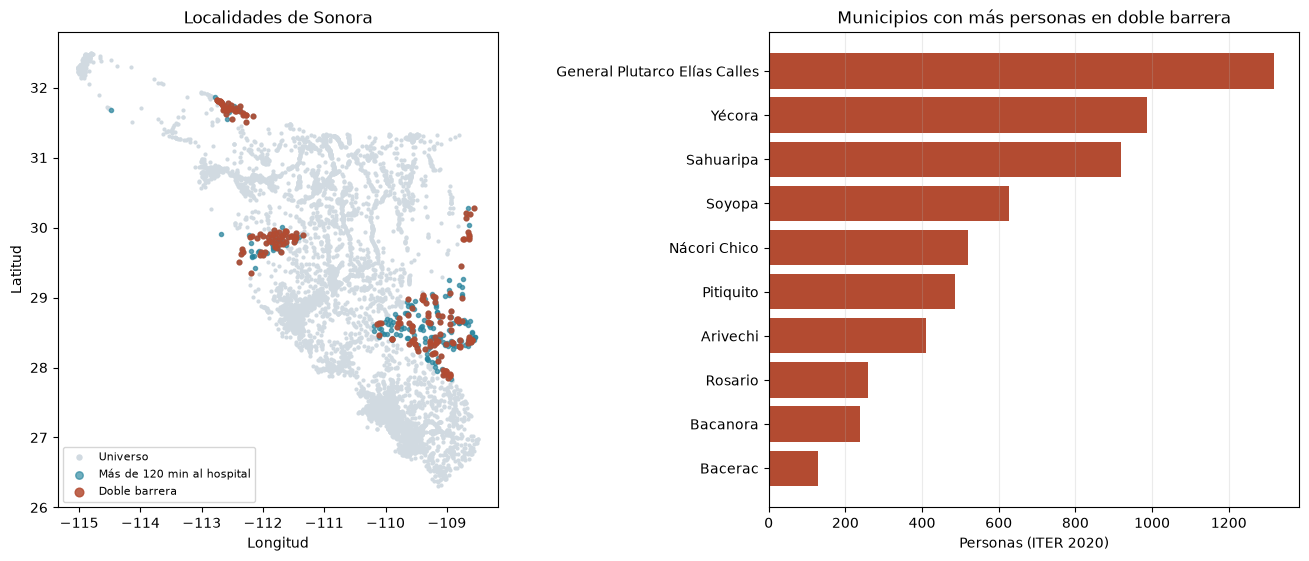

In [4]:
figura, (mapa, barras) = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
mapa.scatter(localidades["longitude"], localidades["latitude"], s=4, c="#d1dae1", label="Universo")
mapa.scatter(lejos["longitude"], lejos["latitude"], s=9, c="#25849d", alpha=.65,
             label=f"Más de {umbral:g} min al hospital")
mapa.scatter(doble["longitude"], doble["latitude"], s=12, c="#b34b31", alpha=.85, label="Doble barrera")
mapa.set(title="Localidades de Sonora", xlabel="Longitud", ylabel="Latitud")
mapa.set_aspect(1 / np.cos(np.deg2rad(localidades["latitude"].median())))
mapa.legend(loc="lower left", fontsize=8, markerscale=1.8)

orden = ranking.head(10).iloc[::-1]
barras.barh(orden.index, orden["personas"], color="#b34b31")
barras.set(title="Municipios con más personas en doble barrera", xlabel="Personas (ITER 2020)")
barras.grid(axis="x", alpha=.25)
plt.show()

## Frecuencia de transporte y marginación

La frecuencia y los minutos a la cabecera se resumen entre localidades que reportaron transporte foráneo. Los porcentajes por grado de marginación usan la población con tiempo hospitalario disponible dentro de cada grado. El grupo sin dato se conserva para mostrar el alcance del cruce.

El umbral se somete a una prueba de sensibilidad. Las cifras muestran cuánto cambia la clasificación cuando se cambia el corte, manteniendo el mismo método de traslado.

,localidades,personas,localidades_con_tiempo,mediana_cabecera_min
frecuencia,,,,
1 A 5,455,76967,447,60.0
15 A 29,103,18151,103,30.0
30 O MAS,57,1876,57,15.0
6 A 14,376,68326,375,35.0
SIN RESPUESTA,1,6,1,7.0
SIN SALIDA DIARIA,50,8091,50,60.0


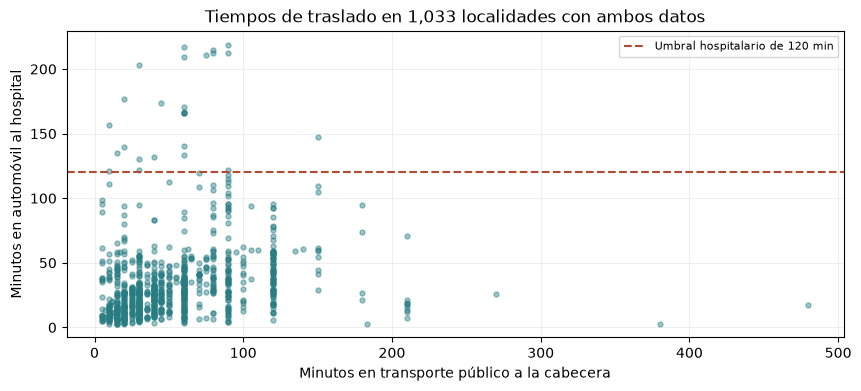

,localidades,personas,personas_demora,personas_doble,% con demora
grado,,,,,
MUY BAJO,749,2646560,15381,1531,0.58
BAJO,606,217156,4152,2644,1.91
MEDIO,282,47950,1211,1076,2.53
ALTO,126,6784,616,372,9.08
MUY ALTO,87,2599,153,37,5.89
SIN DATO,5447,23775,678,302,2.85


,umbral_min,localidades,personas
0,90,438,13325
1,120,195,5962
2,150,50,3061


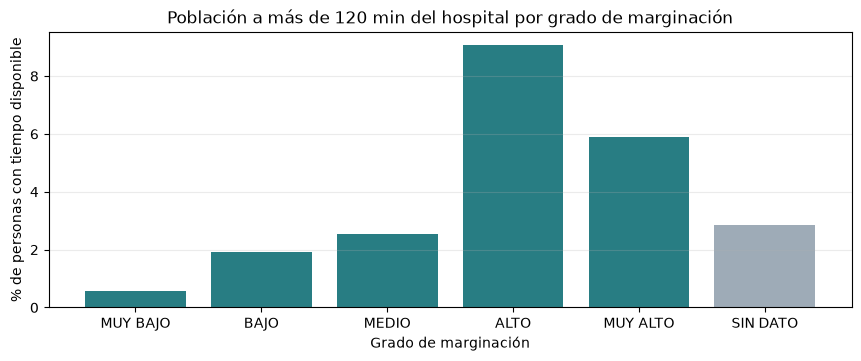

In [5]:
con_transporte = localidades[localidades["estado_transporte"].eq("SI")].copy()
con_transporte["frecuencia"] = con_transporte["frecuencia_salidas_cabecera"].fillna("SIN RESPUESTA")
frecuencia = con_transporte.groupby("frecuencia", observed=True).agg(
    localidades=("locality_id", "size"), personas=("population", "sum"),
    localidades_con_tiempo=("tiempo_cabecera_min", "count"),
    mediana_cabecera_min=("tiempo_cabecera_min", "median")
)
display(frecuencia.round(1))
pares = con_transporte[["tiempo_cabecera_min", "secondary_time_min"]].dropna()
if not pares.empty:
    figura, eje = plt.subplots(figsize=(8.5, 3.8), layout="constrained")
    eje.scatter(pares["tiempo_cabecera_min"], pares["secondary_time_min"], s=13, color="#287d83", alpha=.45)
    eje.axhline(umbral, linestyle="--", color="#b34b31", label=f"Umbral hospitalario de {umbral:g} min")
    eje.set(title=f"Tiempos de traslado en {len(pares):,} localidades con ambos datos",
            xlabel="Minutos en transporte público a la cabecera", ylabel="Minutos en automóvil al hospital")
    eje.legend(fontsize=8)
    eje.grid(alpha=.2)
    plt.show()

evaluables = localidades[localidades["demora"].notna()].copy()
evaluables["grado"] = evaluables["grado"].fillna("SIN DATO")
evaluables["personas_demora"] = evaluables["population"].where(evaluables["demora"], 0)
evaluables["personas_doble"] = evaluables["population"].where(
    evaluables["demora"] & evaluables["estado_transporte"].eq("NO"), 0
)
por_grado = evaluables.groupby("grado", observed=True).agg(
    localidades=("locality_id", "size"), personas=("population", "sum"),
    personas_demora=("personas_demora", "sum"), personas_doble=("personas_doble", "sum")
)
por_grado["% con demora"] = (100 * por_grado["personas_demora"] / por_grado["personas"]).round(2)
orden_grados = ["MUY BAJO", "BAJO", "MEDIO", "ALTO", "MUY ALTO"]
orden_grados += sorted(set(por_grado.index) - set(orden_grados))
por_grado = por_grado.reindex([grado for grado in orden_grados if grado in por_grado.index])
display(por_grado)

sensibilidad = pd.DataFrame([
    {"umbral_min": corte, **resumen(evaluables[evaluables["secondary_time_min"].gt(corte)
                                            & evaluables["estado_transporte"].eq("NO")])}
    for corte in sorted({90, umbral, 150})
])
display(sensibilidad)

figura, ejes = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
colores = ["#9eabb7" if grado == "SIN DATO" else "#287d83" for grado in por_grado.index]
ejes.bar(por_grado.index, por_grado["% con demora"], color=colores)
ejes.set(title=f"Población a más de {umbral:g} min del hospital por grado de marginación",
         ylabel="% de personas con tiempo disponible", xlabel="Grado de marginación")
ejes.grid(axis="y", alpha=.25)
plt.show()